# 00. Audit Data

**Proyek akhir Jaringan Saraf Tiruan: MLP dengan backpropagation**

Notebook ini menjawab empat pertanyaan dasar sebelum modeling:

1. Data apa yang tersedia dan seberapa baik kualitasnya?
2. Target apa yang diprediksi?
3. Kolom mana yang tidak boleh menjadi input?
4. Bagaimana data dibagi menjadi train, validation, dan test?

Belum ada preprocessing yang di-fit dan belum ada training. Jalankan sel secara berurutan. File `data/raw/ev_battery_health.csv` harus sudah tersedia (lihat README repositori).

## 1. Setup

Sel berikut mencari root proyek dan memuat modul `ev_battery.audit`. Seluruh logika audit ada di modul tersebut, sedangkan notebook ini menampilkan dan menjelaskan hasilnya.

In [1]:
from pathlib import Path
import json
import sys
import pandas as pd
from IPython.display import display, Markdown, Image

REPO = next((p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file()), None)
if REPO is None:
    raise RuntimeError("Buka notebook dari root proyek atau folder notebooks.")
if str(REPO / "src") not in sys.path:
    sys.path.insert(0, str(REPO / "src"))
from ev_battery.paths import prepare_workspace

ROOT = prepare_workspace(REPO)
from ev_battery.audit import run_audit, build_split, TARGET, PROXY_COLUMNS

pd.set_option("display.max_columns", 12)
pd.set_option("display.max_colwidth", 85)
pd.set_option("display.precision", 3)
print("Python:", sys.version.split()[0])
print("Dataset lokal dan dokumentasi sumber ditemukan. Data asli tidak dimodifikasi.")

Python: 3.13.1
Dataset lokal dan dokumentasi sumber ditemukan. Data asli tidak dimodifikasi.


## 2. Sumber data dan asumsi

Sumber: [Kaggle EV Battery Health & Degradation](https://www.kaggle.com/datasets/vinay24baghira/ev-battery-health-and-degradation-dataset).

Menurut README di dalam arsip, dataset ini **sepenuhnya sintetis**, berisi 50.000 observasi, dan berlisensi **CC0**. Pengukuran listrik disebut diturunkan dari SOH dan kimia baterai. Ini klaim pembuat dataset, bukan hasil verifikasi kami.

- **Target:** `state_of_health_pct` (SOH dalam persen).
- **Asumsi:** ringkasan pemakaian dan lingkungan sudah diketahui saat observasi. Karena itu tugasnya adalah estimasi SOH saat ini, bukan forecasting.

Audit memeriksa SHA-256 CSV dan kecocokan 35 kolom dengan kamus data. Jika versi CSV atau manifest split berbeda, eksekusi dihentikan.

In [2]:
audit = run_audit(ROOT)
df = audit["frame"]
train = audit["train"]
quality = audit["quality"]
contract = audit["contract"]
print(f"Observasi: {len(df):,}, kolom: {df.shape[1]}, baterai: {df.battery_id.nunique():,}")
print("SHA-256:", contract["dataset_sha256"])
display(df[["battery_id", "observation_id", "observation_date", TARGET]].head())

Observasi: 50,000, kolom: 35, baterai: 2,600
SHA-256: cacdf6afcf50db86583be3754207a89acbfd60b04dfff8f69b71e29cfd78218d


,battery_id,observation_id,observation_date,state_of_health_pct
0,BATT_01748,OBS_033554,2024-10-16,80.87
1,BATT_00491,OBS_009428,2024-12-27,91.81
2,BATT_00011,OBS_000200,2026-02-10,97.48
3,BATT_00651,OBS_012448,2022-09-15,99.18
4,BATT_02054,OBS_039490,2026-03-01,91.86


## 3. Kamus data dan peran kolom

Tabel di bawah menggabungkan kamus data dari sumber dengan hasil audit. Persentase missing value di sini hanya untuk pemeriksaan kualitas, bukan untuk menghitung statistik imputasi.

In [3]:
display(audit["schema"][["column", "dtype", "unit", "description", "missing_count", "missing_pct", "role"]])

,column,dtype,unit,description,missing_count,missing_pct,role
0,battery_id,string,-,"Unique identifier for a physical battery pack (2,600 unique batteries)",0,0.000,excluded
1,observation_id,string,-,Unique identifier for a single longitudinal observation/reading,0,0.000,excluded
2,chemistry,categorical,-,"Cell chemistry: LFP, NMC, NCA, or LMO",3459,6.918,primary_feature
3,manufacturer,categorical,-,Battery pack manufacturer (synthetic brand names),2461,4.922,primary_feature
4,vehicle_model,categorical,-,EV model/platform the pack is installed in,3515,7.030,primary_feature
5,pack_capacity_kwh,float,kWh,Nominal (rated new) pack energy capacity,2302,4.604,primary_feature
6,manufacture_date,date,YYYY-MM-DD,Date the battery pack was manufactured,1910,3.820,excluded
7,observation_date,date,YYYY-MM-DD,Date of this telemetry/health observation,2216,4.432,excluded
8,battery_age_days,int,days,Days elapsed since manufacture at time of observation,3002,6.004,primary_feature
9,cycle_count,int,cycles,Cumulative equivalent full charge cycles at time of observation,2269,4.538,primary_feature


## 4. Integritas ID, tanggal, dan duplikasi

Pemeriksaan yang dilakukan:

- `observation_id` harus unik.
- Duplikasi pasangan baterai dan tanggal hanya dicek pada tanggal yang terisi.
- Urutan tanggal (observasi, manufaktur, servis) harus masuk akal.
- Umur baterai harus cocok dengan selisih tanggal.

Nilai ekstrem tidak dihapus pada tahap ini.

In [4]:
basic = {
    k: quality[k]
    for k in [
        "duplicate_rows",
        "duplicate_observation_ids",
        "missing_targets",
        "missing_observation_dates",
        "duplicate_battery_date_non_null",
        "infinite_numeric_values",
        "observation_before_manufacture",
        "service_after_observation",
        "service_before_manufacture",
        "age_check_eligible",
        "age_date_mismatches",
    ]
}
display(pd.Series(basic, name="jumlah").to_frame())
display(pd.DataFrame(quality["date_ranges"]).T)
display(pd.Series(quality["outside_basic_ranges"], name="di_luar_rentang").to_frame())
display(
    pd.Series(
        quality["within_battery_static_conflicts"], name="baterai_dengan_nilai_statis_berubah"
    ).to_frame()
)
assert quality["duplicate_observation_ids"] == 0
assert quality["missing_targets"] == 0
assert quality["age_date_mismatches"] == 0

,jumlah
duplicate_rows,0
duplicate_observation_ids,0
missing_targets,0
missing_observation_dates,2216
duplicate_battery_date_non_null,0
infinite_numeric_values,0
observation_before_manufacture,0
service_after_observation,0
service_before_manufacture,0
age_check_eligible,43199


,min,max
manufacture_date,2020-09-29,2026-07-29
observation_date,2020-10-07,2026-09-27
last_service_date,2020-10-11,2026-09-27


,di_luar_rentang
state_of_health_pct,0
capacity_fade_pct,0
fast_charge_ratio,0
avg_depth_of_discharge_pct,0
avg_state_of_charge_pct,0
humidity_pct,0
recall_flag,0


,baterai_dengan_nilai_statis_berubah
chemistry,0
manufacturer,0
vehicle_model,0
pack_capacity_kwh,0
manufacture_date,0
climate_zone,0


**Interpretasi:** semua pemeriksaan integritas lolos. Jumlah observasi per baterai adalah 7 sampai 37, sedikit berbeda dari klaim README (10 sampai 40). Angka hasil audit yang dipakai.

## 5. Missing value dan tanggal servis

Tanggal servis yang kosong belum tentu data rusak. Sebagian besar terjadi karena baterai memang belum pernah diservis (`service_count = 0`). Karena itu tanggal servis tidak diimputasi dan tanggal mentah dikeluarkan dari input baseline.

In [5]:
missing = (
    audit["schema"]
    .loc[lambda x: x.missing_count.gt(0), ["column", "missing_count", "missing_pct"]]
    .sort_values("missing_count", ascending=False)
)
display(missing)
service_keys = [
    "service_missing_count_zero",
    "service_missing_count_positive",
    "service_missing_count_missing",
]
display(pd.Series({k: quality[k] for k in service_keys}, name="baris").to_frame())

,column,missing_count,missing_pct
28,last_service_date,18831,37.662
4,vehicle_model,3515,7.030
2,chemistry,3459,6.918
13,fast_charge_ratio,3405,6.810
17,total_energy_throughput_kwh,3370,6.740
18,avg_ambient_temp_c,3282,6.564
15,avg_state_of_charge_pct,3138,6.276
8,battery_age_days,3002,6.004
14,avg_depth_of_discharge_pct,2832,5.664
22,voltage_avg_v,2807,5.614


,baris
service_missing_count_zero,18205
service_missing_count_positive,0
service_missing_count_missing,626


## 6. Kebocoran target (target leakage)

`capacity_fade_pct` didefinisikan sebagai `100 - SOH`. Jika kolom ini menjadi input, model hanya perlu menghitung ulang rumus, bukan belajar. Sel berikut membuktikan identitas tersebut pada semua nilai yang terisi.

Kolom lain yang dikeluarkan:

- `remaining_useful_life_cycles`, `failure_risk_label`, `degradation_category`: target alternatif.
- `battery_id`, `observation_id`: hanya untuk split dan pelacakan.

In [6]:
display(
    pd.Series(
        {
            "baris_capacity_fade_terisi": quality["fade_identity_eligible"],
            "maks_selisih_abs_fade_plus_soh_dari_100": quality["fade_identity_max_abs_error"],
        }
    ).to_frame("hasil")
)
assert quality["fade_identity_max_abs_error"] == 0
forbidden = {
    "capacity_fade_pct",
    "remaining_useful_life_cycles",
    "failure_risk_label",
    "degradation_category",
    "battery_id",
    "observation_id",
    TARGET,
}
assert not forbidden.intersection(contract["primary_features"])
display(pd.DataFrame(contract["excluded_features"].items(), columns=["kolom", "alasan_dikeluarkan"]))

,hasil
baris_capacity_fade_terisi,48131.0
maks_selisih_abs_fade_plus_soh_dari_100,0.0


,kolom,alasan_dikeluarkan
0,battery_id,"Group ID used for splitting, not a feature."
1,observation_id,"Observation ID used for tracking, not a feature."
2,capacity_fade_pct,"Direct identity 100 - SOH, target leakage."
3,remaining_useful_life_cycles,"Alternative target or health label, not an input for SOH regression."
4,failure_risk_label,"Alternative target or health label, not an input for SOH regression."
5,degradation_category,"Alternative target or health label, not an input for SOH regression."
6,manufacture_date,"Raw date excluded from the baseline, battery_age_days is used instead."
7,observation_date,"Raw date excluded from the baseline, battery_age_days is used instead."
8,last_service_date,"Raw date excluded from the baseline, battery_age_days is used instead."
9,internal_resistance_mohm,"Candidate synthetic sensor proxy, only for a separate ablation after reviewing or..."


**Sensor sebagai proxy target:** sumber menyebut pengukuran listrik diturunkan dari SOH, dan internal resistance disebut secara eksplisit. Empat kolom sensor (resistance, voltage, current, charge time) dikeluarkan dari baseline sebagai langkah konservatif. Kolom ini hanya boleh diuji dalam ablation terpisah.

## 7. Struktur berulang dan kelayakan timesteps

Setiap baterai diamati beberapa kali, jadi secara prinsip data bisa disusun sebagai deret waktu. Syaratnya, tanggal harus lengkap dan counter kumulatif (siklus, energi) tidak boleh turun. Sel berikut mengecek kedua syarat itu.

In [7]:
display(pd.Series(quality["observations_per_battery"], name="observasi_per_baterai").to_frame())
temporal = pd.DataFrame(quality["temporal_counter_checks"]).T
temporal["decreasing_pct_of_eligible"] = temporal.decreasing_pairs / temporal.eligible_pairs * 100
display(temporal)
print("Keputusan:", contract["timesteps"])

,observasi_per_baterai
count,2600.000
mean,19.231
std,4.367
min,7.000
25%,16.000
50%,19.000
75%,22.000
max,37.000


,eligible_pairs,decreasing_pairs,decreasing_pct_of_eligible
cycle_count,43017,7820,18.179
battery_age_days,42320,0,0.000
total_energy_throughput_kwh,41948,8923,21.272


Keputusan: Not used: dates are missing and cumulative counters are not always monotonic, requires further temporal audit.


**Interpretasi:** `cycle_count` dan `total_energy_throughput_kwh` cukup sering turun padahal seharusnya kumulatif, dan 2.216 tanggal observasi kosong. Kesimpulannya, input model berupa fitur tabular per observasi dan timesteps tidak dipakai.

## 8. Split per baterai (70/15/15)

Tujuan evaluasi adalah memprediksi SOH **baterai baru** yang tidak pernah dilihat saat training. Jika split dilakukan per baris, observasi dari baterai yang sama bisa muncul di train dan test sehingga hasilnya terlalu optimis.

Prosedur:

1. Urutkan semua `battery_id`.
2. Acak dengan `numpy.random.default_rng(42)`.
3. Bagi 70% train, 15% validation, 15% test berdasarkan jumlah baterai.

Target tidak dipakai dalam proses ini. Manifest disimpan di `data/splits/battery_split.csv`.

In [8]:
display(audit["split_summary"])
groups = {s: set(audit["manifest"].query("split == @s").battery_id) for s in ["train", "validation", "test"]}
assert len(groups["train"]) == 1820
assert len(groups["validation"]) == len(groups["test"]) == 390
assert not groups["train"] & groups["validation"]
assert not groups["train"] & groups["test"]
assert not groups["validation"] & groups["test"]
assert sum(len(x) for x in groups.values()) == df.battery_id.nunique()
manifest_again, row_split_again, _ = build_split(df)
pd.testing.assert_frame_equal(audit["manifest"], manifest_again)
pd.testing.assert_series_equal(audit["row_split"], row_split_again)
print("PASS: grup tidak tumpang tindih, cakupan lengkap, dan split dapat direproduksi.")

,split,batteries,rows,row_pct
0,train,1820,34929,69.858
1,validation,390,7499,14.998
2,test,390,7572,15.144


PASS: grup tidak tumpang tindih, cakupan lengkap, dan split dapat direproduksi.


## 9. Profil awal (train saja)

Mulai dari sini semua statistik dan grafik hanya memakai data train. Validation dan test tidak dilihat agar tidak memengaruhi keputusan desain.

,soh_band_pct,train_rows,train_pct
0,<70,525,1.503
1,70–<80,1697,4.858
2,80–<90,6412,18.357
3,90–<95,8264,23.659
4,>=95,18031,51.622


,column,count,mean,std,min,1%,25%,50%,75%,99%,max
15,state_of_health_pct,34929.0,92.919,7.193,55.0,67.256,90.08,95.23,98.05,100.0,100.0


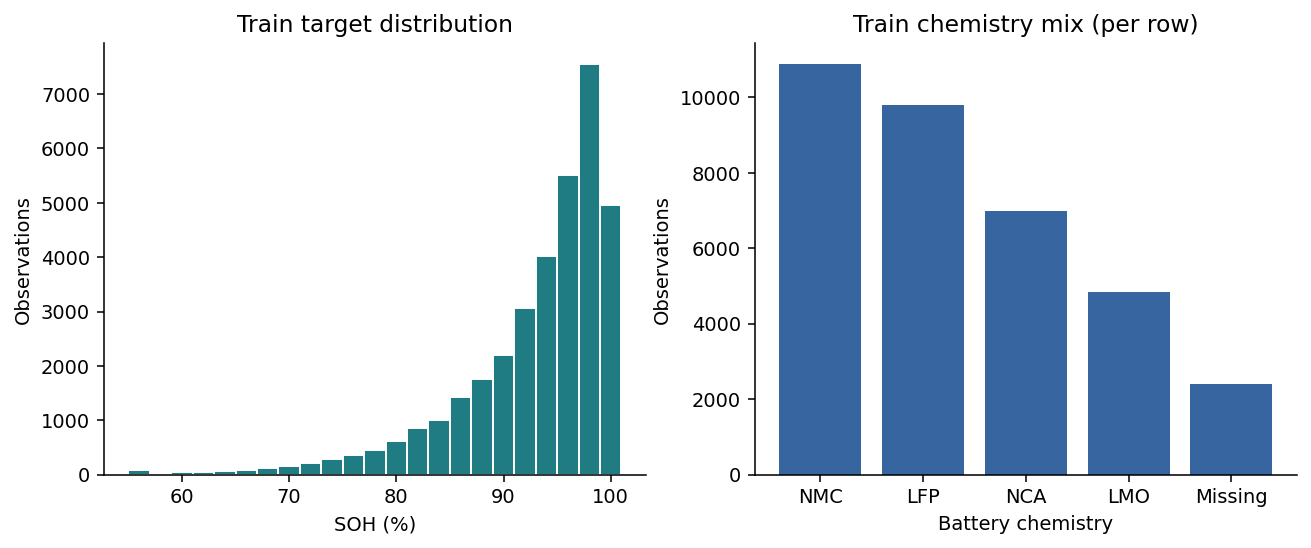

In [9]:
display(audit["bands_train"])
display(audit["statistics_train"].loc[lambda x: x["column"].eq(TARGET)])
display(Image(filename=str(audit["output"] / "02_target_chemistry_train.png"), width=1000))

**Interpretasi:** sebagian besar observasi memiliki SOH tinggi dan hanya sedikit yang berada di bawah 80%. Karena target kontinu, balancing kelas seperti SMOTE tidak relevan. Sebagai gantinya, error akan dilaporkan per rentang SOH.

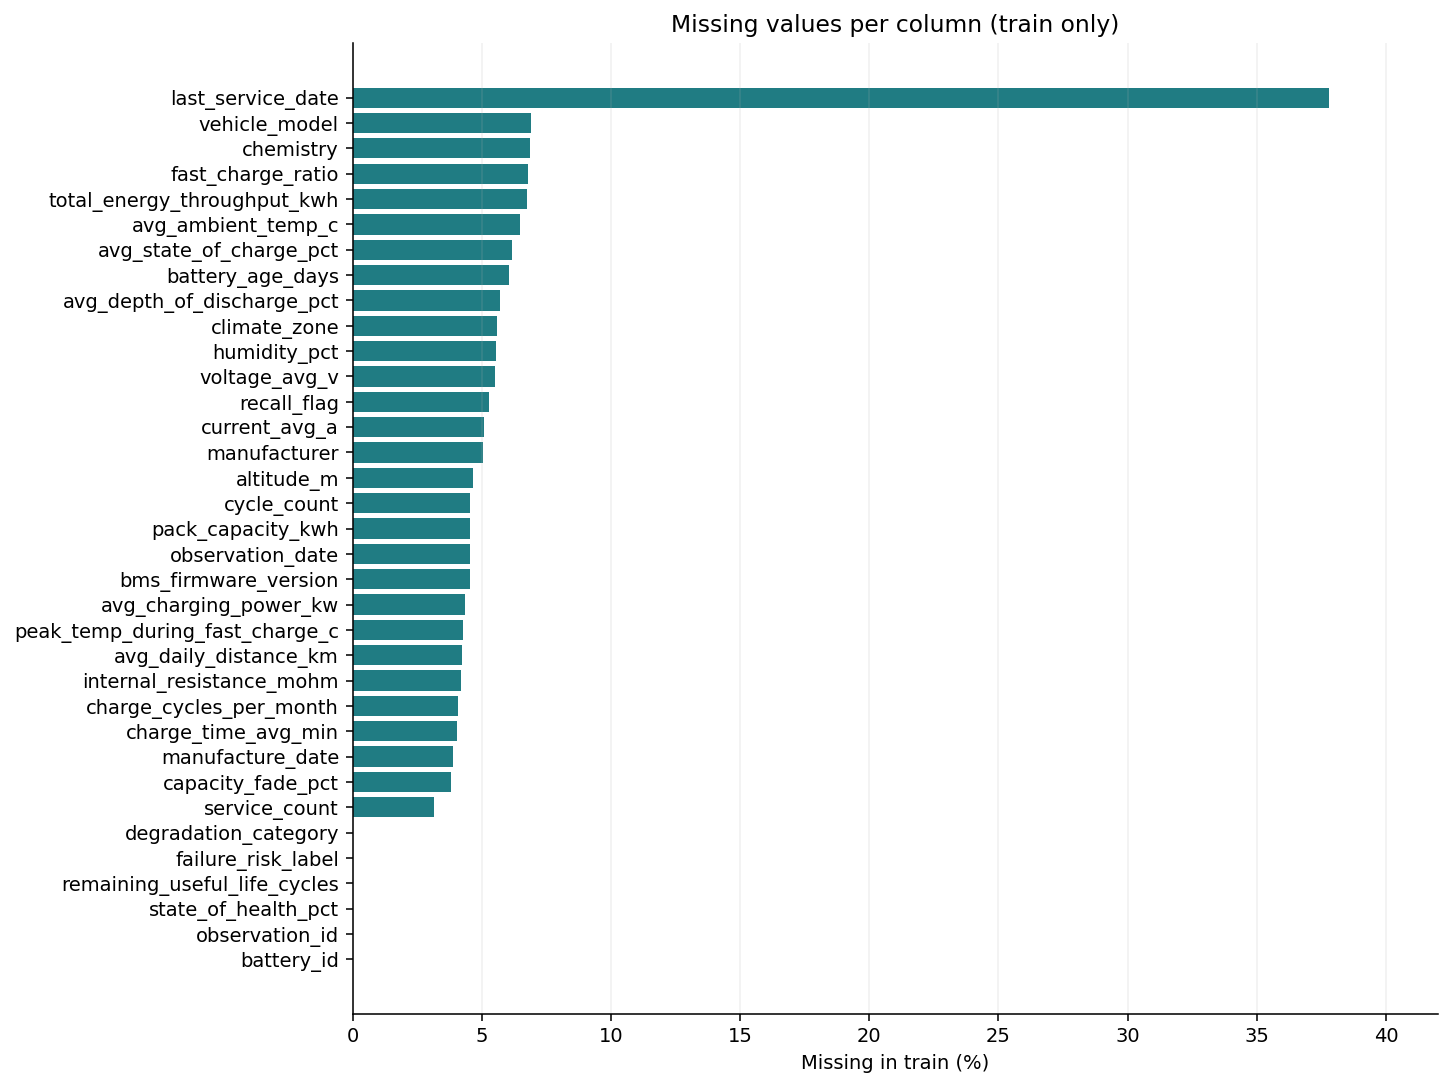

,column,mean,std,min,1%,25%,50%,75%,99%,max
0,pack_capacity_kwh,72.631,14.400,40.100,41.700,62.500,72.500,82.500,99.400,99.900
1,battery_age_days,555.565,476.557,1.000,6.000,167.000,418.000,835.000,1888.870,2184.000
2,cycle_count,572.371,606.371,1.000,4.000,136.000,372.000,800.000,2802.640,5073.000
3,avg_daily_distance_km,50.487,39.826,3.000,4.700,22.500,39.300,66.800,192.657,400.000
4,avg_charging_power_kw,31.975,17.701,1.496,4.200,19.000,28.600,41.800,85.385,147.772
5,fast_charge_ratio,0.293,0.172,0.000,0.000,0.161,0.272,0.405,0.746,0.937
6,avg_depth_of_discharge_pct,64.754,15.820,10.000,26.300,54.100,65.000,75.900,100.000,100.000
7,avg_state_of_charge_pct,67.624,10.127,30.900,43.300,60.800,67.900,74.600,90.300,95.000
8,charge_cycles_per_month,20.307,10.289,2.000,2.000,12.800,19.000,26.600,47.300,57.500
9,total_energy_throughput_kwh,38685.231,42928.649,36.400,292.750,8772.200,24155.300,53217.100,200447.024,402419.900


In [10]:
display(Image(filename=str(audit["output"] / "01_missing_train.png"), width=850))
display(audit["statistics_train"].drop(columns=["count"]).round(3))

**Interpretasi:** skala fitur sangat berbeda, misalnya rasio 0 sampai 1 dibandingkan energi kumulatif dalam ribuan kWh. Ini alasan kuat untuk normalisasi (standardisasi) sebelum training MLP. Parameternya akan di-fit dari train pada notebook 02.

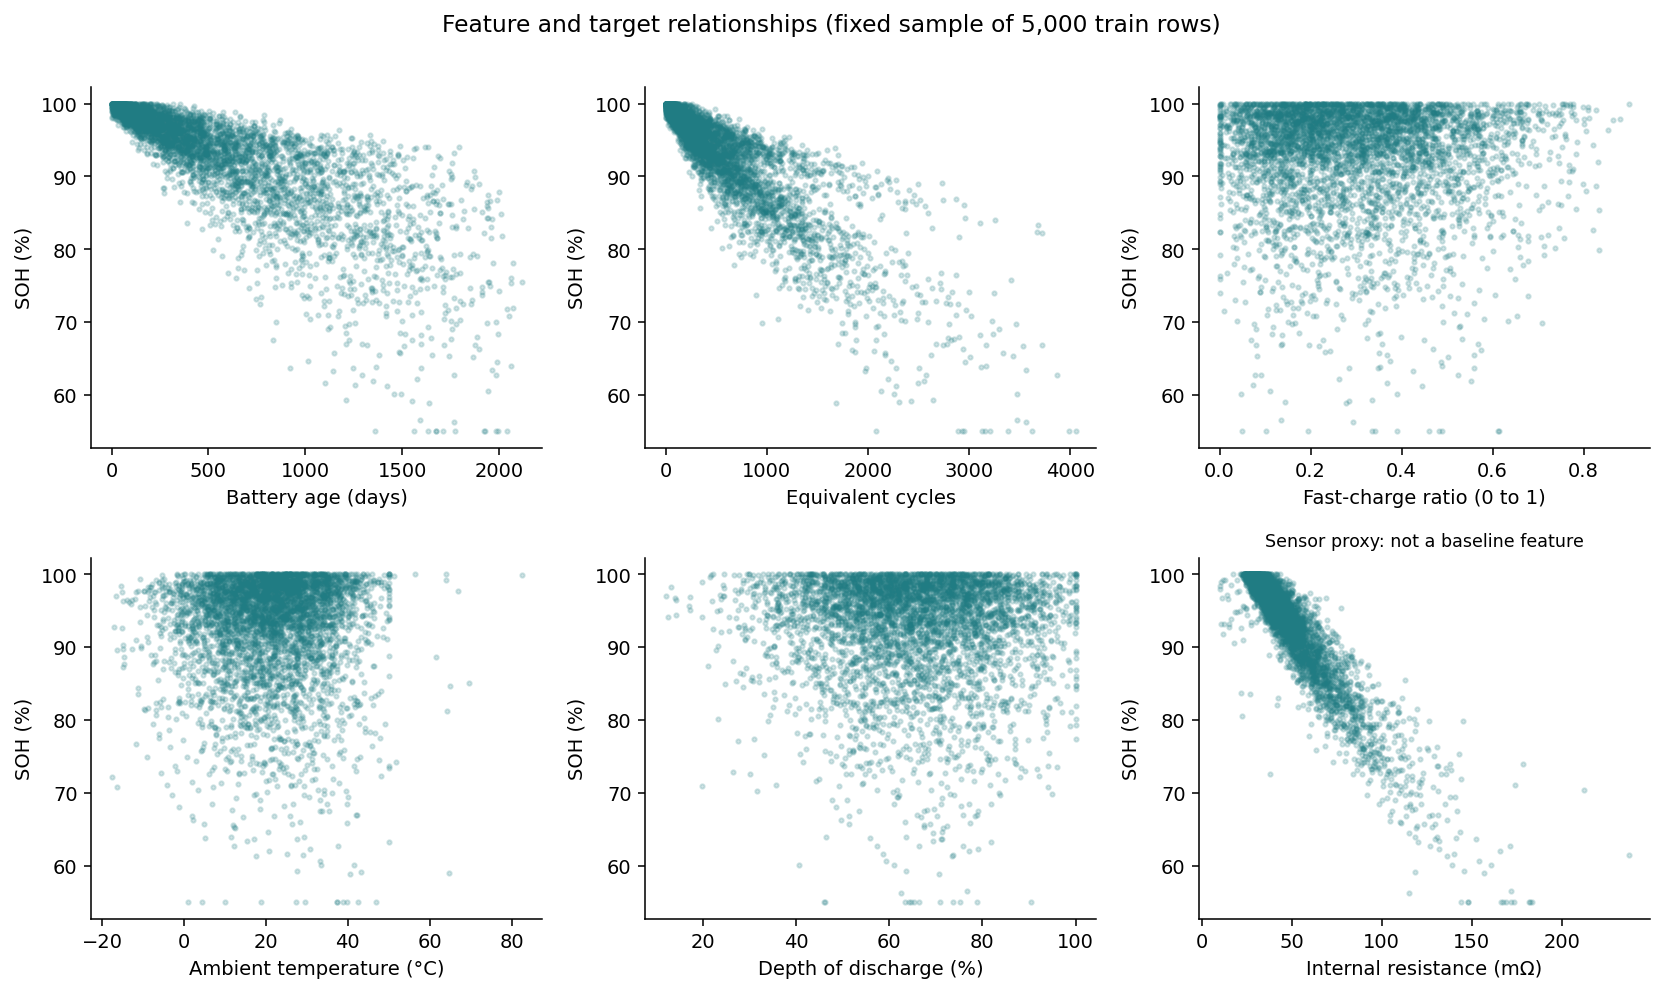

In [11]:
display(Image(filename=str(audit["output"] / "03_relationships_train.png"), width=1100))

**Interpretasi:** umur dan jumlah siklus berhubungan kuat dengan SOH, dan polanya tidak sepenuhnya linear. Ini mendukung penggunaan MLP dengan hidden layer nonlinear. Grafik memakai sampel tetap 5.000 baris train.

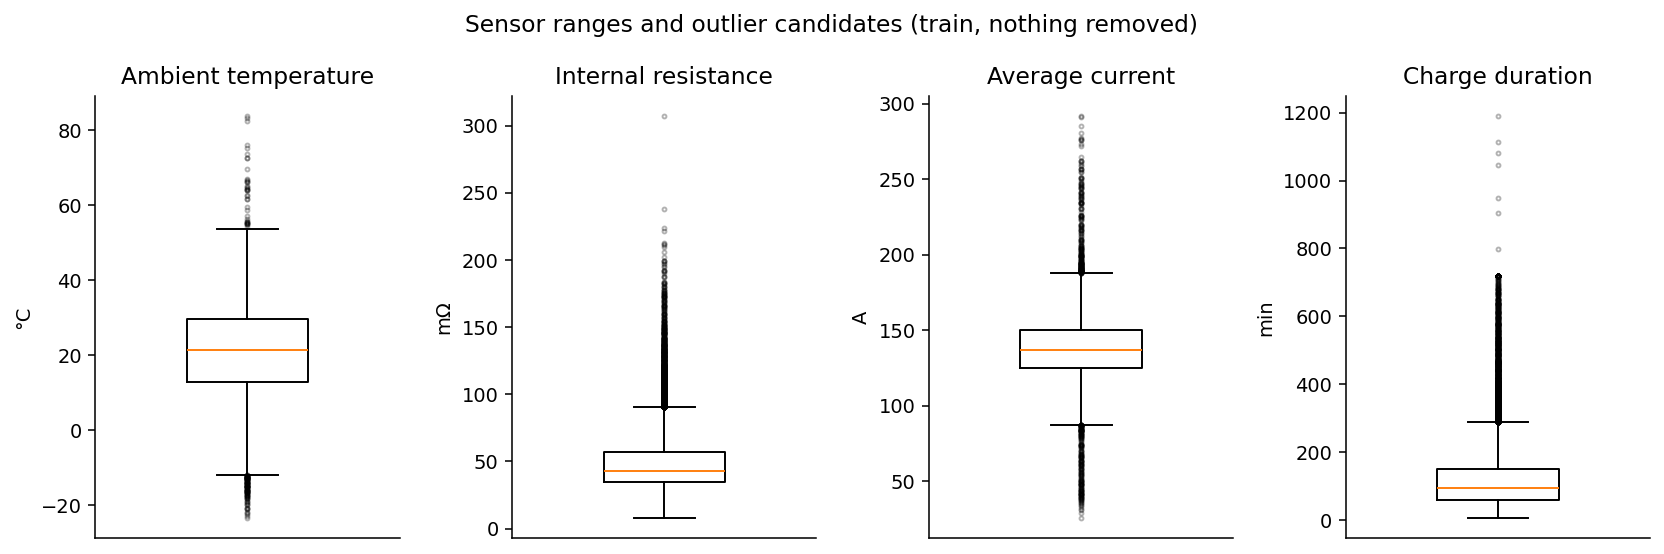

,column,iqr_lower_train,iqr_upper_train,flagged_rows,non_missing_rows,flagged_pct_of_non_missing
19,charge_time_avg_min,-76.300,288.500,2252,33516,6.719
9,total_energy_throughput_kwh,-57895.150,119884.450,1837,32567,5.641
16,internal_resistance_mohm,1.515,90.275,1852,33465,5.534
2,cycle_count,-860.000,1796.000,1684,33337,5.051
15,state_of_health_pct,78.125,110.005,1729,34929,4.950
12,altitude_m,-409.000,911.000,1574,33297,4.727
3,avg_daily_distance_km,-43.950,133.250,1523,33444,4.554
14,service_count,-3.000,5.000,1043,33825,3.084
4,avg_charging_power_kw,-15.200,76.000,787,33416,2.355
18,current_avg_a,87.350,187.750,474,33157,1.430


In [12]:
display(Image(filename=str(audit["output"] / "04_sensor_ranges_train.png"), width=1100))
display(audit["outliers_train"].sort_values("flagged_pct_of_non_missing", ascending=False).round(3))

**Interpretasi:** titik di luar batas 1,5×IQR adalah kandidat outlier, bukan pasti data salah. Tidak ada outlier yang dihapus di tahap ini. Penanganannya dibandingkan sebagai resep preprocessing di notebook 02.

## 10. Kontrak fitur baseline

Ada 21 fitur mentah yang boleh dipakai: 15 numerik, 5 kategori, dan 1 biner (`recall_flag`). Jumlah input neuron nantinya lebih besar dari 21 karena one-hot encoding dan indikator missing value.

In [13]:
roles = [
    ("numerik", contract["numeric_features"]),
    ("kategori", contract["categorical_features"]),
    ("biner", contract["binary_features"]),
]
feature_rows = [{"tipe": kind, "kolom": c} for kind, columns in roles for c in columns]
display(pd.DataFrame(feature_rows))
assert len(feature_rows) == len(contract["primary_features"]) == 21
assert len({row["kolom"] for row in feature_rows}) == 21
assert set(row["kolom"] for row in feature_rows) == set(contract["primary_features"])
print("15 numerik + 5 kategori + 1 biner. Input p ditentukan setelah preprocessing.")

,tipe,kolom
0,numerik,pack_capacity_kwh
1,numerik,battery_age_days
2,numerik,cycle_count
3,numerik,avg_daily_distance_km
4,numerik,avg_charging_power_kw
5,numerik,fast_charge_ratio
6,numerik,avg_depth_of_discharge_pct
7,numerik,avg_state_of_charge_pct
8,numerik,charge_cycles_per_month
9,numerik,total_energy_throughput_kwh


15 numerik + 5 kategori + 1 biner. Input p ditentukan setelah preprocessing.


## 11. Artefak yang dihasilkan

- `results/audit/AUDIT_REPORT.md`: ringkasan temuan.
- `results/audit/schema_audit.csv`: kamus 35 kolom beserta perannya.
- `results/audit/quality_summary.json`: hasil pemeriksaan kualitas dan temporal.
- `results/audit/provenance.json`: versi library dan hash data.
- `configs/feature_contract.json`: target dan daftar fitur.
- `data/splits/battery_split.csv`: manifest split.

In [14]:
expected = [ROOT / "configs/feature_contract.json", ROOT / "data/splits/battery_split.csv"]
expected += [
    audit["output"] / name
    for name in [
        "AUDIT_REPORT.md",
        "schema_audit.csv",
        "quality_summary.json",
        "provenance.json",
        "numeric_train.csv",
        "outlier_flags_train.csv",
        "target_bands_train.csv",
    ]
]
assert all(path.is_file() for path in expected)
provenance = json.loads((audit["output"] / "provenance.json").read_text(encoding="utf-8"))
assert provenance["dataset_sha256"] == contract["dataset_sha256"]
print("PASS: artefak audit lengkap dan terikat pada versi dataset yang sama.")
display(pd.Series(provenance["packages"], name="versi").to_frame())

PASS: artefak audit lengkap dan terikat pada versi dataset yang sama.


,versi
numpy,2.2.5
pandas,2.3.2
matplotlib,3.10.6
nbformat,5.10.4
nbclient,0.10.2
ipykernel,6.29.5


## 12. Kesimpulan

- Target: SOH saat observasi, dievaluasi pada baterai baru.
- Split per baterai: 1.820 train, 390 validation, 390 test.
- 21 fitur mentah boleh dipakai. Kolom yang membocorkan target dan proxy sensor dikeluarkan.
- Timesteps tidak dipakai karena kualitas urutan waktu tidak memadai.

**Berikutnya:** `01_eda.ipynb` mendalami distribusi, korelasi, missing value, dan outlier pada train.